# Sumativa 2 — Bootstrap de medias y correlaciones

**Equipo:** Hernán Saavedra, Lenin Salas y Rodrigo Gómez.  
**Responsable de este bloque:** Lenin Salas.

## Objetivo

Evaluar, mediante bootstrap no paramétrico, la estabilidad de las estimaciones
de la Sumativa 1:

1. Medias de ingreso mensual, edad y antigüedad, con intervalos del 95 %
   por percentil y BCa, comparados con los intervalos t de la referencia S1.
2. Las cuatro correlaciones de Spearman de referencia, remuestreando las filas
   completas para conservar el emparejamiento de cada par de variables.

Se utiliza el dataset IBM HR original completo, sin faltantes artificiales.
El notebook carga sus propios datos, fija sus generadores aleatorios y se
ejecuta desde cero, sin depender del notebook de Monte Carlo.
Los archivos `S1_referencia_*.csv` solo se leen; no se modifican.

### Idea del bootstrap

La muestra observada se trata como una aproximación de la población.
Se extraen B muestras **con reemplazo** del mismo tamaño n = 1.470, se
recalcula el estadístico en cada una y la distribución de esas B réplicas
aproxima la distribución muestral del estimador, sin suponer normalidad.

In [1]:
from pathlib import Path
import hashlib
import json
import sys

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Buscar la raíz desde cualquier carpeta dentro del repositorio.
nombre_csv = "WA_Fn-UseC_-HR-Employee-Attrition.csv"
carpeta_actual = Path.cwd().resolve()

raiz = next(
    (
        carpeta
        for carpeta in [carpeta_actual, *carpeta_actual.parents]
        if (carpeta / "datos" / nombre_csv).is_file()
    ),
    None
)

if raiz is None:
    raise FileNotFoundError(
        "No se encontró el dataset en la carpeta datos del repositorio."
    )

ruta_datos = raiz / "datos" / nombre_csv
carpeta_figuras = raiz / "S2" / "figuras"
carpeta_resultados = raiz / "S2" / "resultados"

carpeta_figuras.mkdir(parents=True, exist_ok=True)
carpeta_resultados.mkdir(parents=True, exist_ok=True)

# Cargar el original y trabajar sobre una copia.
original = pd.read_csv(ruta_datos)
df = original.copy(deep=True)

# Configuración de reproducibilidad.
SEMILLA = 42
B = 10_000          # remuestras bootstrap por variable y por par
ALFA = 0.05         # intervalos del 95 %
N = len(df)

sns.set_theme(style="whitegrid")

huella_csv = hashlib.sha256(ruta_datos.read_bytes()).hexdigest()

print("Raíz del repositorio:", raiz)
print("Registros:", N, "| Columnas:", df.shape[1])
print("Remuestras por estadístico:", f"{B:,}".replace(",", "."))
print("Python", sys.version.split()[0], "| pandas", pd.__version__,
      "| NumPy", np.__version__, "| SciPy", scipy.__version__,
      "| Matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)

Raíz del repositorio: /home/claude/estadisticaComputacional
Registros: 1470 | Columnas: 35
Remuestras por estadístico: 10.000
Python 3.13.16 | pandas 3.0.6 | NumPy 2.4.6 | SciPy 1.17.1 | Matplotlib 3.11.2 | seaborn 0.13.2


## 1. Lectura y verificación de las referencias S1

Se leen las referencias exportadas en el bloque de Hernán y se verifica,
con las huellas SHA-256 de `S1_trazabilidad.json`, que el dataset y las
referencias no cambiaron. Si alguna huella no coincide, el notebook se detiene. La comparación
normaliza los saltos de línea, porque Git puede convertirlos según el sistema
operativo de quien clona el repositorio.

In [2]:
def leer_csv(ruta):
    """Lee un CSV de referencia conservando todos los decimales."""
    return pd.read_csv(
        ruta, encoding="utf-8-sig", float_precision="round_trip"
    )

def sha256(ruta):
    return hashlib.sha256(ruta.read_bytes()).hexdigest()


def sha256_crlf(ruta):
    """Huella con saltos de línea CRLF, como en S1_trazabilidad.json.

    Git puede guardar los CSV con LF (Linux/macOS) o CRLF (Windows) según la
    configuración de cada integrante; el contenido es el mismo. Se normaliza
    a CRLF para comparar con las huellas registradas en Windows.
    """
    contenido = ruta.read_bytes().replace(b"\r\n", b"\n")
    return hashlib.sha256(contenido.replace(b"\n", b"\r\n")).hexdigest()

trazabilidad = json.loads(
    (carpeta_resultados / "S1_trazabilidad.json").read_text(encoding="utf-8")
)

assert sha256_crlf(ruta_datos) == trazabilidad["dataset"]["sha256"], (
    "El dataset no coincide con el usado en S1."
)

for referencia in trazabilidad["referencias"]:
    ruta = raiz / referencia["ruta"]
    assert sha256_crlf(ruta) == referencia["sha256"], (
        f"La referencia cambió: {ruta.name}"
    )

# Huellas al inicio, para comprobar al final que no se modificaron.
huellas_referencias = {
    ruta.name: sha256(ruta)
    for ruta in sorted(carpeta_resultados.glob("S1_referencia_*.csv"))
}

ref_medias = leer_csv(carpeta_resultados / "S1_referencia_medias.csv")
ref_correlaciones = leer_csv(
    carpeta_resultados / "S1_referencia_correlaciones.csv"
)

print("Dataset y referencias verificados contra S1_trazabilidad.json.")
display(ref_medias)
display(ref_correlaciones)

Dataset y referencias verificados contra S1_trazabilidad.json.


,variable,n,media,desviacion_estandar,error_estandar,ic95_inferior,ic95_superior,metodo
0,MonthlyIncome,1470,6502.931293,4707.956783,122.793054,6262.062872,6743.799713,t de Student
1,Age,1470,36.923810,9.135373,0.238269,36.456426,37.391193,t de Student
2,YearsAtCompany,1470,7.008163,6.126525,0.159792,6.694718,7.321608,t de Student


,variable_x,variable_y,n,rho_spearman
0,MonthlyIncome,TotalWorkingYears,1470,0.710024
1,Age,TotalWorkingYears,1470,0.656896
2,YearsAtCompany,TotalWorkingYears,1470,0.594193
3,DistanceFromHome,MonthlyIncome,1470,0.002512


## 2. Funciones de intervalo: percentil y BCa

**Percentil.** Los límites son los cuantiles 2,5 % y 97,5 % de las B réplicas
$\hat\theta^*_1,\dots,\hat\theta^*_B$.

**BCa (bias-corrected and accelerated).** Ajusta qué cuantiles se usan con dos
correcciones:

- **Sesgo** $\hat z_0 = \Phi^{-1}\!\left(\frac{\#\{\hat\theta^*_b < \hat\theta\}}{B}\right)$:
  mide si las réplicas quedan sistemáticamente por debajo o por encima del
  estimador original ($\Phi^{-1}$ es la inversa de la normal estándar).
- **Aceleración** $\hat a = \dfrac{\sum_i (\bar\theta_{(\cdot)}-\hat\theta_{(i)})^3}
  {6\left[\sum_i (\bar\theta_{(\cdot)}-\hat\theta_{(i)})^2\right]^{3/2}}$,
  calculada por jackknife ($\hat\theta_{(i)}$ es el estimador sin la observación $i$):
  capta la asimetría y el cambio del error estándar con el parámetro.

Los cuantiles ajustados son
$\alpha_{1,2} = \Phi\!\left(\hat z_0 + \dfrac{\hat z_0 + z_{\alpha/2,\,1-\alpha/2}}
{1-\hat a(\hat z_0 + z_{\alpha/2,\,1-\alpha/2})}\right)$.
Si $\hat z_0 = \hat a = 0$, BCa coincide con el percentil.

In [3]:
def ic_percentil(replicas, alfa=ALFA):
    return np.quantile(replicas, [alfa / 2, 1 - alfa / 2])


def ic_bca(replicas, estimador, jackknife, alfa=ALFA):
    """Intervalo BCa a partir de réplicas bootstrap y valores jackknife."""
    # Corrección de sesgo; los empates se reparten por mitades.
    proporcion = (
        np.mean(replicas < estimador)
        + 0.5 * np.mean(replicas == estimador)
    )
    z0 = stats.norm.ppf(proporcion)

    # Aceleración por jackknife.
    d = jackknife.mean() - jackknife
    a = np.sum(d ** 3) / (6 * np.sum(d ** 2) ** 1.5)

    z = stats.norm.ppf([alfa / 2, 1 - alfa / 2])
    cuantiles = stats.norm.cdf(z0 + (z0 + z) / (1 - a * (z0 + z)))

    return np.quantile(replicas, cuantiles), z0, a, cuantiles

## 3. Bootstrap no paramétrico de las medias

En cada una de las 10.000 iteraciones se sortean 1.470 índices de fila con
reemplazo y se calcula la media de cada variable. El generador es exclusivo de
este bloque (`SeedSequence([42, 2])`); Hernán usa `[42, 1]` para Monte Carlo,
así ambos procedimientos son independientes del orden de ejecución.

Para la media, el jackknife tiene forma cerrada:
$\bar x_{(i)} = (\sum x - x_i)/(n-1)$.

In [4]:
variables_medias = ref_medias["variable"].tolist()

rng_medias = np.random.default_rng(np.random.SeedSequence([SEMILLA, 2]))
indices_medias = rng_medias.integers(0, N, size=(B, N))

replicas_medias = {}
filas_medias = []

for variable in variables_medias:
    x = df[variable].to_numpy(dtype=float)
    media = x.mean()

    replicas = x[indices_medias].mean(axis=1)
    replicas_medias[variable] = replicas

    jackknife = (x.sum() - x) / (N - 1)

    p_inf, p_sup = ic_percentil(replicas)
    (b_inf, b_sup), z0, a, cuantiles = ic_bca(replicas, media, jackknife)

    ref = ref_medias.set_index("variable").loc[variable]

    filas_medias.append({
        "variable": variable,
        "n": N,
        "B": B,
        "media": media,
        "media_s1": ref["media"],
        "media_bootstrap": replicas.mean(),
        "sesgo_bootstrap": replicas.mean() - media,
        "ee_bootstrap": replicas.std(ddof=1),
        "ee_s1": ref["error_estandar"],
        "razon_ee": replicas.std(ddof=1) / ref["error_estandar"],
        "asimetria_replicas": stats.skew(replicas),
        "t_inferior": ref["ic95_inferior"],
        "t_superior": ref["ic95_superior"],
        "percentil_inferior": p_inf,
        "percentil_superior": p_sup,
        "bca_inferior": b_inf,
        "bca_superior": b_sup,
        "bca_z0": z0,
        "bca_aceleracion": a,
        "bca_cuantil_inferior": cuantiles[0],
        "bca_cuantil_superior": cuantiles[1],
    })

bootstrap_medias = pd.DataFrame(filas_medias)

# La media original debe coincidir con la referencia de S1.
assert np.allclose(bootstrap_medias["media"], bootstrap_medias["media_s1"])

columnas_vista = [
    "variable", "media", "ee_s1", "ee_bootstrap", "razon_ee",
    "t_inferior", "t_superior", "percentil_inferior", "percentil_superior",
    "bca_inferior", "bca_superior", "bca_z0", "bca_aceleracion"
]
display(bootstrap_medias[columnas_vista].round(4))

,variable,media,ee_s1,ee_bootstrap,razon_ee,t_inferior,t_superior,percentil_inferior,percentil_superior,bca_inferior,bca_superior,bca_z0,bca_aceleracion
0,MonthlyIncome,6502.9313,122.7931,120.9942,0.9854,6262.0629,6743.7997,6265.7370,6741.6580,6271.3202,6747.3013,0.0123,0.0059
1,Age,36.9238,0.2383,0.2365,0.9924,36.4564,37.3912,36.4633,37.3939,36.4701,37.3997,0.0075,0.0018
2,YearsAtCompany,7.0082,0.1598,0.1600,1.0012,6.6947,7.3216,6.7027,7.3224,6.7095,7.3294,0.0103,0.0077


### 3.1 Comparación de los tres intervalos

Para que la comparación sea interpretable entre variables con escalas distintas
(pesos, años), cada diferencia se expresa también en **unidades de error estándar
de S1**: una diferencia de 0,05 EE significa que el límite se movió un 5 % del
error estándar.

In [5]:
filas_comparacion = []

for _, fila in bootstrap_medias.iterrows():
    ancho_t = fila["t_superior"] - fila["t_inferior"]

    for metodo in ["t", "percentil", "bca"]:
        inferior = fila[f"{metodo}_inferior"]
        superior = fila[f"{metodo}_superior"]

        filas_comparacion.append({
            "variable": fila["variable"],
            "metodo": {"t": "t de Student (S1)",
                       "percentil": "Bootstrap percentil",
                       "bca": "Bootstrap BCa"}[metodo],
            "ic95_inferior": inferior,
            "ic95_superior": superior,
            "ancho": superior - inferior,
            "razon_ancho_vs_t": (superior - inferior) / ancho_t,
            "dif_inferior_vs_t": inferior - fila["t_inferior"],
            "dif_superior_vs_t": superior - fila["t_superior"],
            "dif_inferior_en_ee": (inferior - fila["t_inferior"]) / fila["ee_s1"],
            "dif_superior_en_ee": (superior - fila["t_superior"]) / fila["ee_s1"],
            # Asimetría del intervalo: >1 si el lado superior es más largo.
            "razon_colas": (superior - fila["media"]) / (fila["media"] - inferior),
        })

comparacion_medias = pd.DataFrame(filas_comparacion)

presentacion = comparacion_medias.copy()
for columna in presentacion.columns[2:]:
    presentacion[columna] = presentacion[columna].map(
        lambda valor: f"{valor:.4f}".replace(".", ",")
    )
display(presentacion)

,variable,metodo,ic95_inferior,ic95_superior,ancho,razon_ancho_vs_t,dif_inferior_vs_t,dif_superior_vs_t,dif_inferior_en_ee,dif_superior_en_ee,razon_colas
0,MonthlyIncome,t de Student (S1),"6262,0629","6743,7997","481,7368","1,0000","0,0000","0,0000","0,0000","0,0000","1,0000"
1,MonthlyIncome,Bootstrap percentil,"6265,7370","6741,6580","475,9210","0,9879","3,6741","-2,1417","0,0299","-0,0174","1,0065"
2,MonthlyIncome,Bootstrap BCa,"6271,3202","6747,3013","475,9811","0,9881","9,2573","3,5016","0,0754","0,0285","1,0551"
3,Age,t de Student (S1),"36,4564","37,3912","0,9348","1,0000","0,0000","0,0000","0,0000","0,0000","1,0000"
4,Age,Bootstrap percentil,"36,4633","37,3939","0,9306","0,9956","0,0068","0,0027","0,0287","0,0113","1,0207"
5,Age,Bootstrap BCa,"36,4701","37,3997","0,9297","0,9945","0,0136","0,0085","0,0573","0,0359","1,0489"
6,YearsAtCompany,t de Student (S1),"6,6947","7,3216","0,6269","1,0000","0,0000","0,0000","0,0000","0,0000","1,0000"
7,YearsAtCompany,Bootstrap percentil,"6,7027","7,3224","0,6197","0,9886","0,0080","0,0008","0,0501","0,0053","1,0290"
8,YearsAtCompany,Bootstrap BCa,"6,7095","7,3294","0,6199","0,9888","0,0148","0,0078","0,0927","0,0489","1,0757"


### 3.2 Validación cruzada con `scipy.stats.bootstrap`

Como control de la implementación manual de BCa, se calcula el mismo intervalo
con SciPy y un generador independiente (`[42, 4]`). Al usar remuestras distintas
los límites no serán idénticos; deben diferir solo por error Monte Carlo
(una fracción pequeña del error estándar).

In [6]:
rng_scipy = np.random.default_rng(np.random.SeedSequence([SEMILLA, 4]))
filas_control = []

for _, fila in bootstrap_medias.iterrows():
    x = df[fila["variable"]].to_numpy(dtype=float)
    resultado = stats.bootstrap(
        (x,), np.mean, n_resamples=B, method="BCa",
        confidence_level=1 - ALFA, random_state=rng_scipy
    )
    ic = resultado.confidence_interval
    filas_control.append({
        "variable": fila["variable"],
        "bca_manual_inferior": fila["bca_inferior"],
        "bca_scipy_inferior": ic.low,
        "bca_manual_superior": fila["bca_superior"],
        "bca_scipy_superior": ic.high,
        "dif_max_en_ee": max(
            abs(fila["bca_inferior"] - ic.low),
            abs(fila["bca_superior"] - ic.high)
        ) / fila["ee_s1"],
    })

control_scipy = pd.DataFrame(filas_control)
display(control_scipy.round(4))

# Tolerancia: diferencias menores a 0,15 errores estándar.
assert (control_scipy["dif_max_en_ee"] < 0.15).all()
print("La implementación manual de BCa concuerda con SciPy.")

,variable,bca_manual_inferior,bca_scipy_inferior,bca_manual_superior,bca_scipy_superior,dif_max_en_ee
0,MonthlyIncome,6271.3202,6273.1182,6747.3013,6745.5398,0.0146
1,Age,36.4701,36.4578,37.3997,37.4004,0.0514
2,YearsAtCompany,6.7095,6.7015,7.3294,7.3381,0.0542


La implementación manual de BCa concuerda con SciPy.


### 3.3 Distribuciones bootstrap de las medias

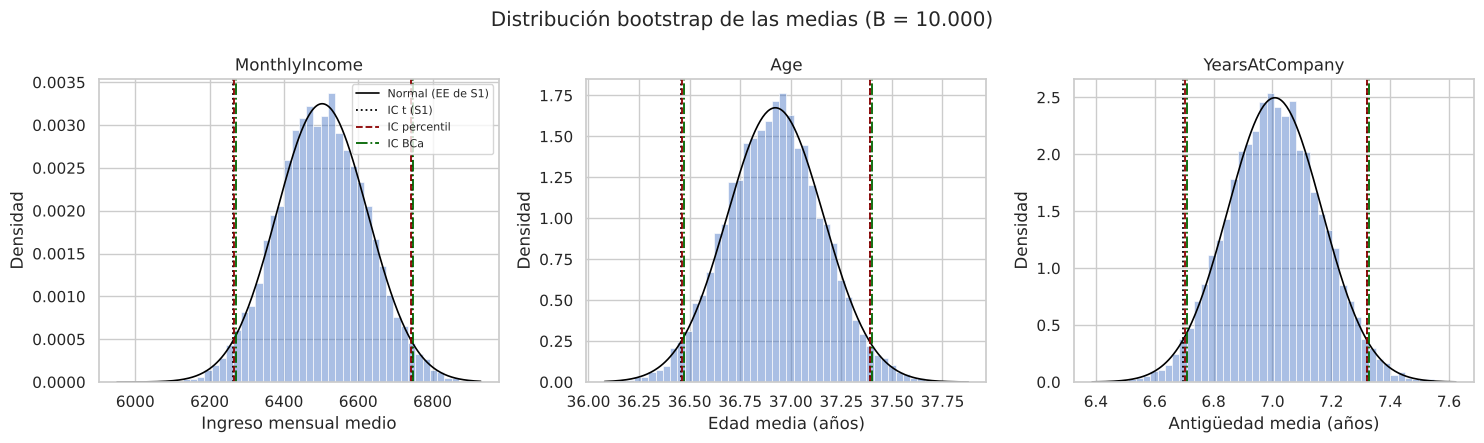

Figura guardada: S2/figuras/lenin_bootstrap_medias_distribuciones.png


In [7]:
etiquetas = {
    "MonthlyIncome": "Ingreso mensual medio",
    "Age": "Edad media (años)",
    "YearsAtCompany": "Antigüedad media (años)",
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, (_, fila) in zip(axes, bootstrap_medias.iterrows()):
    replicas = replicas_medias[fila["variable"]]

    sns.histplot(replicas, bins=50, stat="density",
                 color="#4472C4", alpha=0.45, ax=ax)

    # Curva normal implícita en el intervalo t de S1.
    malla = np.linspace(replicas.min(), replicas.max(), 300)
    ax.plot(malla, stats.norm.pdf(malla, fila["media"], fila["ee_s1"]),
            color="black", lw=1.2, label="Normal (EE de S1)")

    estilos = [("t", "black", ":", "IC t (S1)"),
               ("percentil", "darkred", "--", "IC percentil"),
               ("bca", "darkgreen", "-.", "IC BCa")]
    for metodo, color, linea, etiqueta in estilos:
        for k, lado in enumerate(["inferior", "superior"]):
            ax.axvline(fila[f"{metodo}_{lado}"], color=color, ls=linea,
                       lw=1.3, label=etiqueta if k == 0 else None)

    ax.set_xlabel(etiquetas[fila["variable"]])
    ax.set_ylabel("Densidad")
    ax.set_title(fila["variable"])

axes[0].legend(fontsize=8)
fig.suptitle(f"Distribución bootstrap de las medias (B = {B:,})".replace(",", "."))
fig.tight_layout()

ruta = carpeta_figuras / "lenin_bootstrap_medias_distribuciones.png"
fig.savefig(ruta, dpi=150, bbox_inches="tight")
plt.show()
print("Figura guardada:", ruta.relative_to(raiz).as_posix())

### Interpretación: medias

**Error estándar.** El error estándar bootstrap coincide con el analítico de S1 (s/√n): la razón es 0,985 para ingreso, 0,992 para edad y 1,001 para antigüedad. Las diferencias, de 1,5 % o menos, provienen sobre todo de la variación del propio remuestreo; el bootstrap no supone normalidad y llega al mismo valor.

**Intervalos percentil frente a t.** Los intervalos percentil son entre 0,4 % y 1,2 % más angostos que los t, y sus límites se desplazan como máximo 0,05 errores estándar. Para el ingreso mensual, el intervalo t es [6.262; 6.744] y el percentil [6.266; 6.742]. La diferencia práctica es nula.

**Intervalos BCa.** BCa desplaza los tres intervalos levemente hacia la derecha (z₀ y aceleración positivos) y alarga la cola superior entre 5 % y 8 % respecto de la inferior. Es la huella de la asimetría positiva de las variables, más marcada en ingreso y antigüedad: unos pocos sueldos o antigüedades altas pueden elevar la media de una remuestra más de lo que los valores bajos pueden reducirla. El mayor desplazamiento es de 0,09 errores estándar (límite inferior de antigüedad); en ingreso, el intervalo BCa es [6.271; 6.747], unos $9 por encima del t en el límite inferior.

**Lectura de las discrepancias.** Aunque el ingreso mensual no es normal (figura QQ de S1), con n = 1.470 la distribución de su *media* sí es casi normal: la asimetría de las réplicas es 0,01 a 0,04 y el histograma se superpone con la curva normal de S1. Por eso los tres métodos concuerdan y los intervalos t de S1 se mantienen como válidos. La implementación manual de BCa concuerda con `scipy.stats.bootstrap` dentro de 0,05 errores estándar.

## 4. Bootstrap de las correlaciones de Spearman

Para cada remuestra se sortean **filas completas**: el empleado i conserva su
par (x_i, y_i). Remuestrear cada variable por separado destruiría la asociación
y produciría correlaciones cercanas a cero.

Spearman equivale a la correlación de Pearson entre los rangos. En cada
remuestra se recalculan los rangos (con promedio en los empates, igual que
`pandas` y `scipy`), porque las observaciones repetidas cambian el orden.

Generador exclusivo: `SeedSequence([42, 3])`. Los mismos índices se usan para
los cuatro pares, lo que equivale a remuestrear empleados del dataset.

In [8]:
def spearman_por_fila(X, Y):
    """Spearman para cada fila de dos matrices (B x n)."""
    rx = stats.rankdata(X, axis=1)
    ry = stats.rankdata(Y, axis=1)
    rx -= rx.mean(axis=1, keepdims=True)
    ry -= ry.mean(axis=1, keepdims=True)
    return (rx * ry).sum(axis=1) / np.sqrt(
        (rx ** 2).sum(axis=1) * (ry ** 2).sum(axis=1)
    )


def spearman_jackknife(x, y):
    """Spearman omitiendo una observación a la vez."""
    mascara = ~np.eye(len(x), dtype=bool)
    X = np.broadcast_to(x, (len(x), len(x)))[mascara].reshape(len(x), -1)
    Y = np.broadcast_to(y, (len(y), len(y)))[mascara].reshape(len(y), -1)
    return spearman_por_fila(X, Y)


rng_correlaciones = np.random.default_rng(np.random.SeedSequence([SEMILLA, 3]))
indices_correlaciones = rng_correlaciones.integers(0, N, size=(B, N))

replicas_correlaciones = {}
filas_correlaciones = []

for _, ref in ref_correlaciones.iterrows():
    vx, vy = ref["variable_x"], ref["variable_y"]
    x = df[vx].to_numpy(dtype=float)
    y = df[vy].to_numpy(dtype=float)

    rho = stats.spearmanr(x, y).statistic
    assert np.isclose(rho, ref["rho_spearman"]), "No coincide con S1."

    replicas = spearman_por_fila(x[indices_correlaciones],
                                 y[indices_correlaciones])
    replicas_correlaciones[(vx, vy)] = replicas

    p_inf, p_sup = ic_percentil(replicas)
    (b_inf, b_sup), z0, a, _ = ic_bca(replicas, rho,
                                       spearman_jackknife(x, y))

    filas_correlaciones.append({
        "variable_x": vx,
        "variable_y": vy,
        "n": N,
        "B": B,
        "rho_s1": ref["rho_spearman"],
        "rho_bootstrap_media": replicas.mean(),
        "sesgo_bootstrap": replicas.mean() - rho,
        "ee_bootstrap": replicas.std(ddof=1),
        "percentil_inferior": p_inf,
        "percentil_superior": p_sup,
        "bca_inferior": b_inf,
        "bca_superior": b_sup,
        "bca_z0": z0,
        "bca_aceleracion": a,
        "ancho_bca": b_sup - b_inf,
        "proporcion_replicas_positivas": np.mean(replicas > 0),
        "ic_bca_incluye_cero": bool(b_inf <= 0 <= b_sup),
    })

bootstrap_correlaciones = pd.DataFrame(filas_correlaciones)
display(bootstrap_correlaciones.round(4))

,variable_x,variable_y,n,B,rho_s1,rho_bootstrap_media,sesgo_bootstrap,ee_bootstrap,percentil_inferior,percentil_superior,bca_inferior,bca_superior,bca_z0,bca_aceleracion,ancho_bca,proporcion_replicas_positivas,ic_bca_incluye_cero
0,MonthlyIncome,TotalWorkingYears,1470,10000,0.7100,0.7098,-0.0002,0.0153,0.6791,0.7394,0.6788,0.7392,0.0023,-0.0054,0.0604,1.0000,False
1,Age,TotalWorkingYears,1470,10000,0.6569,0.6566,-0.0003,0.0168,0.6231,0.6881,0.6227,0.6880,0.0058,-0.0062,0.0653,1.0000,False
2,YearsAtCompany,TotalWorkingYears,1470,10000,0.5942,0.5941,-0.0001,0.0216,0.5509,0.6349,0.5495,0.6340,-0.0186,-0.0082,0.0845,1.0000,False
3,DistanceFromHome,MonthlyIncome,1470,10000,0.0025,0.0025,-0.0000,0.0259,-0.0479,0.0529,-0.0482,0.0527,-0.0038,0.0002,0.1009,0.5409,True


### 4.1 Estabilidad de las correlaciones

Se resume la estabilidad de cada correlación con tres indicadores:

- **Coeficiente de variación** del bootstrap (EE / |ρ|): qué tan grande es la
  incertidumbre frente a la magnitud de la correlación.
- **Estabilidad del signo**: proporción de réplicas con el mismo signo que ρ.
- **Estabilidad de la intensidad**: proporción de réplicas que caen en la misma
  categoría descriptiva (|ρ| < 0,1 despreciable; 0,1–0,3 débil; 0,3–0,5
  moderada; 0,5–0,7 fuerte; ≥ 0,7 muy fuerte). Los cortes son convencionales;
  una correlación cerca de un corte será inestable en categoría aunque sea
  precisa.

Además, se revisa si los límites del intervalo percentil se estabilizan al
aumentar B (500 a 10.000), usando las primeras B réplicas.

In [9]:
cortes = [0, 0.1, 0.3, 0.5, 0.7, 1.0001]
nombres = ["despreciable", "débil", "moderada", "fuerte", "muy fuerte"]

def categoria(valor):
    return pd.cut(np.abs(np.atleast_1d(valor)), bins=cortes,
                  labels=nombres, right=False).astype(str)

filas_estabilidad = []

for _, fila in bootstrap_correlaciones.iterrows():
    replicas = replicas_correlaciones[(fila["variable_x"], fila["variable_y"])]
    rho = fila["rho_s1"]
    categoria_rho = categoria(rho)[0]
    categorias_replicas = pd.Series(categoria(replicas))

    filas_estabilidad.append({
        "par": f'{fila["variable_x"]} – {fila["variable_y"]}',
        "rho_s1": rho,
        "categoria_s1": categoria_rho,
        "ee_bootstrap": fila["ee_bootstrap"],
        "coef_variacion": fila["ee_bootstrap"] / abs(rho),
        "estabilidad_signo": np.mean(np.sign(replicas) == np.sign(rho)),
        "estabilidad_categoria": np.mean(categorias_replicas == categoria_rho),
        "categorias_observadas": ", ".join(
            f"{k}: {v:.2%}".replace(".", ",")
            for k, v in categorias_replicas.value_counts(normalize=True).items()
        ),
    })

estabilidad_correlaciones = pd.DataFrame(filas_estabilidad)
display(estabilidad_correlaciones.round(4))

# Estabilidad de los límites percentil según el número de remuestras.
filas_b = []
for (vx, vy), replicas in replicas_correlaciones.items():
    for b in [500, 1_000, 2_000, 5_000, 10_000]:
        inferior, superior = ic_percentil(replicas[:b])
        filas_b.append({"variable_x": vx, "variable_y": vy, "B": b,
                        "ee_bootstrap": replicas[:b].std(ddof=1),
                        "percentil_inferior": inferior,
                        "percentil_superior": superior})

convergencia_b = pd.DataFrame(filas_b)
display(convergencia_b.round(4))

,par,rho_s1,categoria_s1,ee_bootstrap,coef_variacion,estabilidad_signo,estabilidad_categoria,categorias_observadas
0,MonthlyIncome – TotalWorkingYears,0.7100,muy fuerte,0.0153,0.0216,1.0000,0.7394,"muy fuerte: 73,94%, fuerte: 26,06%"
1,Age – TotalWorkingYears,0.6569,fuerte,0.0168,0.0255,1.0000,0.9959,"fuerte: 99,59%, muy fuerte: 0,41%"
2,YearsAtCompany – TotalWorkingYears,0.5942,fuerte,0.0216,0.0364,1.0000,1.0000,"fuerte: 100,00%"
3,DistanceFromHome – MonthlyIncome,0.0025,despreciable,0.0259,10.3107,0.5409,0.9996,"despreciable: 99,96%, débil: 0,04%"


,variable_x,variable_y,B,ee_bootstrap,percentil_inferior,percentil_superior
0,MonthlyIncome,TotalWorkingYears,500,0.0156,0.6792,0.7392
1,MonthlyIncome,TotalWorkingYears,1000,0.0158,0.6787,0.7394
2,MonthlyIncome,TotalWorkingYears,2000,0.0154,0.6793,0.7391
3,MonthlyIncome,TotalWorkingYears,5000,0.0154,0.6790,0.7393
4,MonthlyIncome,TotalWorkingYears,10000,0.0153,0.6791,0.7394
5,Age,TotalWorkingYears,500,0.0168,0.6208,0.6861
6,Age,TotalWorkingYears,1000,0.0171,0.6214,0.6891
7,Age,TotalWorkingYears,2000,0.0168,0.6227,0.6884
8,Age,TotalWorkingYears,5000,0.0167,0.6230,0.6885
9,Age,TotalWorkingYears,10000,0.0168,0.6231,0.6881


### 4.2 ¿Es estable el orden entre las correlaciones?

Los intervalos de ingreso–experiencia y edad–experiencia se superponen levemente,
pero eso no basta para concluir que no difieren: ambos se calculan sobre los
mismos empleados y no son independientes. Como los cuatro pares se remuestrearon
con **los mismos índices**, se puede calcular la diferencia entre correlaciones
dentro de cada remuestra y obtener su intervalo percentil directamente.

In [10]:
etiquetas_pares = {
    ("MonthlyIncome", "TotalWorkingYears"): "Ingreso–Experiencia",
    ("Age", "TotalWorkingYears"): "Edad–Experiencia",
    ("YearsAtCompany", "TotalWorkingYears"): "Antigüedad–Experiencia",
}
claves = list(etiquetas_pares)

filas_diferencias = []
for i in range(len(claves)):
    for j in range(i + 1, len(claves)):
        a, b = claves[i], claves[j]
        diferencia = replicas_correlaciones[a] - replicas_correlaciones[b]
        inferior, superior = ic_percentil(diferencia)
        filas_diferencias.append({
            "comparacion": f"{etiquetas_pares[a]} − {etiquetas_pares[b]}",
            "diferencia_observada": (
                bootstrap_correlaciones.set_index(["variable_x", "variable_y"])
                .loc[a, "rho_s1"]
                - bootstrap_correlaciones.set_index(["variable_x", "variable_y"])
                .loc[b, "rho_s1"]
            ),
            "ee_bootstrap": diferencia.std(ddof=1),
            "percentil_inferior": inferior,
            "percentil_superior": superior,
            "proporcion_mayor": np.mean(diferencia > 0),
        })

diferencias_correlaciones = pd.DataFrame(filas_diferencias)
display(diferencias_correlaciones.round(4))

,comparacion,diferencia_observada,ee_bootstrap,percentil_inferior,percentil_superior,proporcion_mayor
0,Ingreso–Experiencia − Edad–Experiencia,0.0531,0.0191,0.0157,0.0905,0.9971
1,Ingreso–Experiencia − Antigüedad–Experiencia,0.1158,0.0243,0.0693,0.1642,1.0000
2,Edad–Experiencia − Antigüedad–Experiencia,0.0627,0.0275,0.0090,0.1173,0.9889


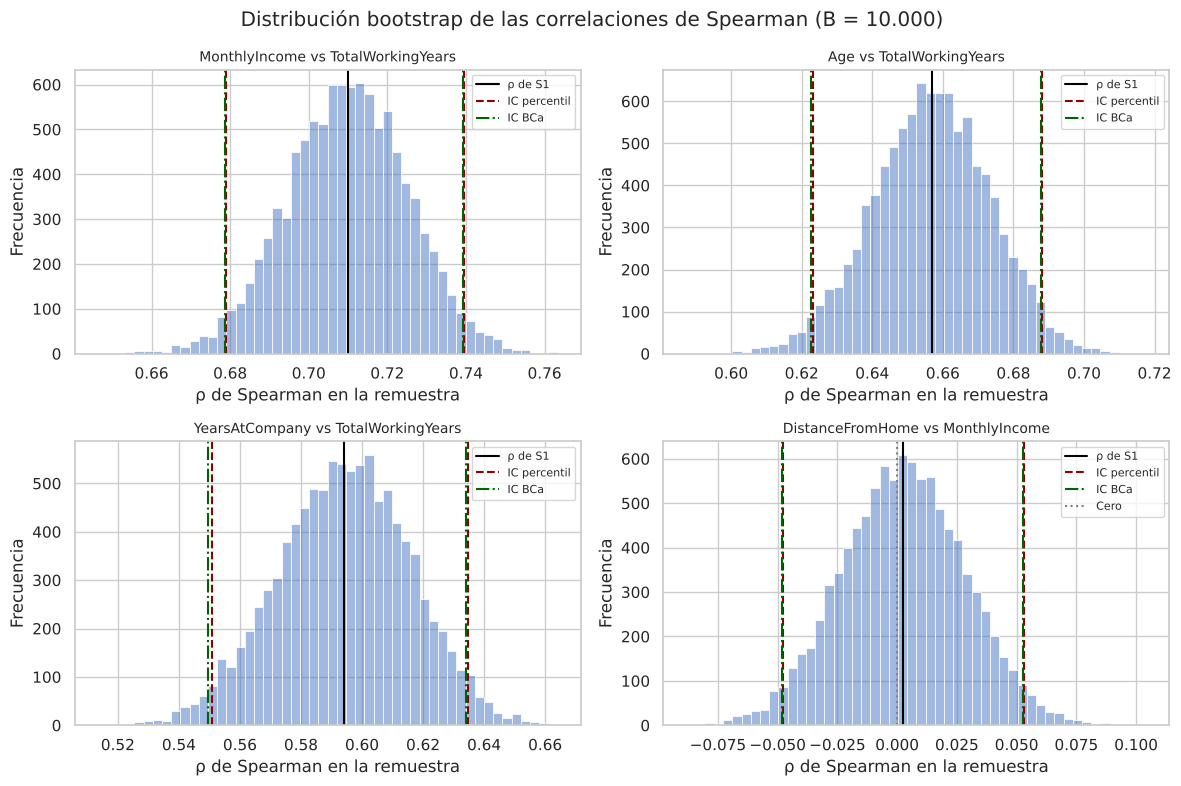

Figura guardada: S2/figuras/lenin_bootstrap_correlaciones_distribuciones.png


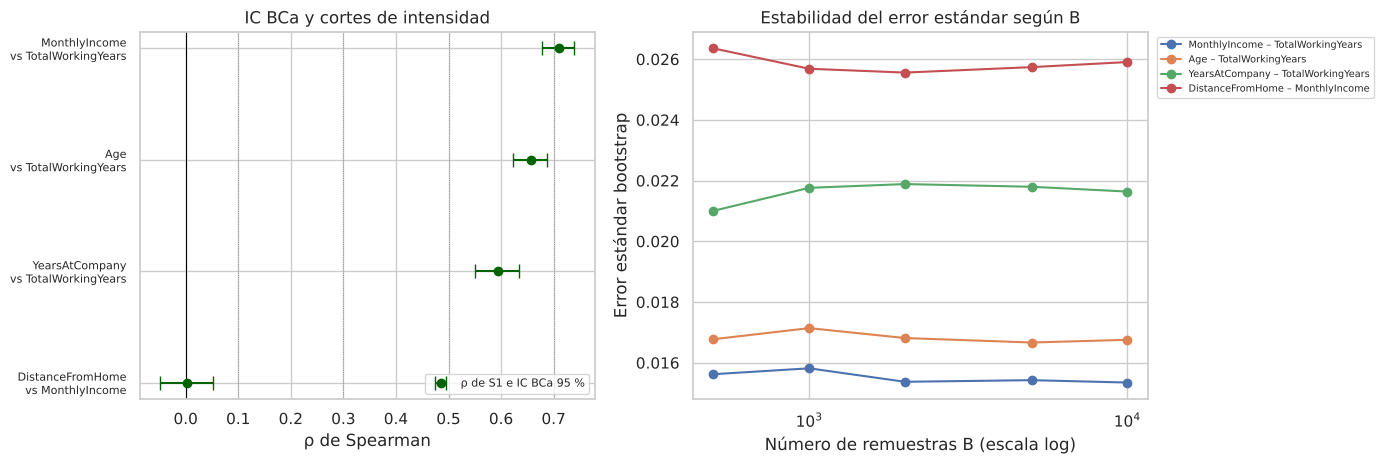

Figura guardada: S2/figuras/lenin_bootstrap_correlaciones_estabilidad.png


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (_, fila) in zip(axes.ravel(), bootstrap_correlaciones.iterrows()):
    replicas = replicas_correlaciones[(fila["variable_x"], fila["variable_y"])]

    sns.histplot(replicas, bins=50, color="#4472C4", alpha=0.5, ax=ax)
    ax.axvline(fila["rho_s1"], color="black", lw=1.5, label="ρ de S1")
    for k, lado in enumerate(["inferior", "superior"]):
        ax.axvline(fila[f"percentil_{lado}"], color="darkred", ls="--",
                   label="IC percentil" if k == 0 else None)
        ax.axvline(fila[f"bca_{lado}"], color="darkgreen", ls="-.",
                   label="IC BCa" if k == 0 else None)
    if fila["ic_bca_incluye_cero"]:
        ax.axvline(0, color="grey", ls=":", label="Cero")

    ax.set_title(f'{fila["variable_x"]} vs {fila["variable_y"]}', fontsize=10)
    ax.set_xlabel("ρ de Spearman en la remuestra")
    ax.set_ylabel("Frecuencia")
    ax.legend(fontsize=8)

fig.suptitle(
    f"Distribución bootstrap de las correlaciones de Spearman (B = {B:,})"
    .replace(",", ".")
)
fig.tight_layout()
ruta = carpeta_figuras / "lenin_bootstrap_correlaciones_distribuciones.png"
fig.savefig(ruta, dpi=150, bbox_inches="tight")
plt.show()
print("Figura guardada:", ruta.relative_to(raiz).as_posix())

# Intervalos en una escala común y estabilidad respecto de B.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

ax = axes[0]
pares = bootstrap_correlaciones.apply(
    lambda f: f'{f["variable_x"]}\nvs {f["variable_y"]}', axis=1
)
posiciones = np.arange(len(bootstrap_correlaciones))
ax.errorbar(
    bootstrap_correlaciones["rho_s1"], posiciones,
    xerr=[bootstrap_correlaciones["rho_s1"] - bootstrap_correlaciones["bca_inferior"],
          bootstrap_correlaciones["bca_superior"] - bootstrap_correlaciones["rho_s1"]],
    fmt="o", color="darkgreen", capsize=5, label="ρ de S1 e IC BCa 95 %"
)
for corte in [0.1, 0.3, 0.5, 0.7]:
    ax.axvline(corte, color="grey", lw=0.6, ls=":")
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(posiciones, pares, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("ρ de Spearman")
ax.set_title("IC BCa y cortes de intensidad")
ax.legend(fontsize=8, loc="lower right")

ax = axes[1]
for (vx, vy), datos in convergencia_b.groupby(["variable_x", "variable_y"], sort=False):
    ax.plot(datos["B"], datos["ee_bootstrap"], marker="o", label=f"{vx} – {vy}")
ax.set_xscale("log")
ax.set_xlabel("Número de remuestras B (escala log)")
ax.set_ylabel("Error estándar bootstrap")
ax.set_title("Estabilidad del error estándar según B")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1))

fig.tight_layout()
ruta = carpeta_figuras / "lenin_bootstrap_correlaciones_estabilidad.png"
fig.savefig(ruta, dpi=150, bbox_inches="tight")
plt.show()
print("Figura guardada:", ruta.relative_to(raiz).as_posix())

### Interpretación: correlaciones

**Precisión.** El sesgo bootstrap es despreciable (|sesgo| ≤ 0,0003) y los errores estándar van de 0,015 a 0,026. Percentil y BCa difieren en menos de 0,0015, porque las distribuciones bootstrap son casi simétricas (z₀ y aceleración cercanos a cero).

**Las tres correlaciones con la experiencia total son estables.**

| Par | ρ S1 | IC BCa 95 % |
|---|---|---|
| Ingreso – experiencia | 0,710 | [0,679; 0,739] |
| Edad – experiencia | 0,657 | [0,623; 0,688] |
| Antigüedad – experiencia | 0,594 | [0,550; 0,634] |

Todas las réplicas son positivas y el coeficiente de variación está entre 2 % y 4 %. El orden también es estable: al comparar dentro de cada remuestra, ingreso–experiencia supera a edad–experiencia en el 99,7 % de las réplicas (diferencia 0,053; IC [0,016; 0,091]), y edad–experiencia supera a antigüedad–experiencia en el 98,9 % (diferencia 0,063; IC [0,009; 0,117]). Aunque los intervalos individuales de ingreso y edad se superponen, la diferencia pareada no incluye el cero.

**Estabilidad de la etiqueta frente a la del valor.** ρ = 0,710 para ingreso–experiencia queda justo sobre el corte convencional de 0,7: el 26 % de las réplicas cae en “fuerte” y el 74 % en “muy fuerte”. El valor es preciso, pero la etiqueta no; conviene informarla como una asociación fuerte, de 0,68 a 0,74, en vez de afirmar “muy fuerte”.

**Distancia – ingreso.** El intervalo BCa [−0,048; 0,053] incluye el cero y solo el 54 % de las réplicas es positivo: el signo es inestable, como lanzar una moneda. Lo que sí es estable es la conclusión: el 99,96 % de las réplicas queda en |ρ| < 0,1. Los datos descartan una asociación monótona de magnitud relevante. El coeficiente de variación (10,3) no es útil aquí porque ρ está prácticamente en cero.

**Número de remuestras.** Desde B = 2.000 el error estándar varía menos de 2 % y, entre 5.000 y 10.000 remuestras, los límites percentil cambian en la tercera decimal. Las 10.000 remuestras son suficientes para estos intervalos.

**Alcance.** Las tres correlaciones altas comparten la variable experiencia total, que se acumula con la edad y con los años en la empresa; parte de la asociación es estructural. Spearman mide asociación monótona, no causalidad, y los datos son sintéticos.

## 5. Exportación de resultados

Tablas sin redondear (`%.17g`), en UTF-8 con BOM, igual que las referencias S1.
Las réplicas se exportan para que el equipo pueda rehacer gráficos o integrar
resultados sin volver a remuestrear.

In [12]:
exportaciones = {
    "lenin_bootstrap_medias_ic.csv": bootstrap_medias,
    "lenin_bootstrap_medias_comparacion.csv": comparacion_medias,
    "lenin_bootstrap_medias_control_scipy.csv": control_scipy,
    "lenin_bootstrap_medias_replicas.csv": pd.DataFrame(
        {"remuestra": np.arange(1, B + 1), **replicas_medias}
    ),
    "lenin_bootstrap_correlaciones_ic.csv": bootstrap_correlaciones,
    "lenin_bootstrap_correlaciones_estabilidad.csv": estabilidad_correlaciones,
    "lenin_bootstrap_correlaciones_convergencia_b.csv": convergencia_b,
    "lenin_bootstrap_correlaciones_diferencias.csv": diferencias_correlaciones,
    "lenin_bootstrap_correlaciones_replicas.csv": pd.DataFrame(
        {"remuestra": np.arange(1, B + 1),
         **{f"{vx}__{vy}": r for (vx, vy), r in replicas_correlaciones.items()}}
    ),
}

for nombre, tabla in exportaciones.items():
    ruta = carpeta_resultados / nombre
    tabla.to_csv(ruta, index=False, encoding="utf-8-sig", float_format="%.17g")
    print("Tabla guardada:", ruta.relative_to(raiz).as_posix())

Tabla guardada: S2/resultados/lenin_bootstrap_medias_ic.csv
Tabla guardada: S2/resultados/lenin_bootstrap_medias_comparacion.csv
Tabla guardada: S2/resultados/lenin_bootstrap_medias_control_scipy.csv
Tabla guardada: S2/resultados/lenin_bootstrap_medias_replicas.csv
Tabla guardada: S2/resultados/lenin_bootstrap_correlaciones_ic.csv
Tabla guardada: S2/resultados/lenin_bootstrap_correlaciones_estabilidad.csv
Tabla guardada: S2/resultados/lenin_bootstrap_correlaciones_convergencia_b.csv
Tabla guardada: S2/resultados/lenin_bootstrap_correlaciones_diferencias.csv
Tabla guardada: S2/resultados/lenin_bootstrap_correlaciones_replicas.csv


## 6. Verificación de reproducibilidad

Se regeneran los índices con las mismas semillas y se comprueba que las réplicas
son idénticas. También se verifica que el dataset y las referencias S1 no
cambiaron durante la ejecución.

In [13]:
rng_verificacion = np.random.default_rng(np.random.SeedSequence([SEMILLA, 2]))
indices_verificacion = rng_verificacion.integers(0, N, size=(B, N))
for variable, replicas in replicas_medias.items():
    x = df[variable].to_numpy(dtype=float)
    assert np.array_equal(replicas, x[indices_verificacion].mean(axis=1))

rng_verificacion = np.random.default_rng(np.random.SeedSequence([SEMILLA, 3]))
indices_verificacion = rng_verificacion.integers(0, N, size=(B, N))
assert np.array_equal(indices_verificacion, indices_correlaciones)

assert sha256(ruta_datos) == huella_csv
assert df.equals(original)
for nombre, huella in huellas_referencias.items():
    assert sha256(carpeta_resultados / nombre) == huella, nombre

print("Reproducibilidad: correcta.")
print("Dataset original y referencias S1: sin modificaciones.")
print(f"Remuestras por estadístico: {B:,}".replace(",", "."))

Reproducibilidad: correcta.
Dataset original y referencias S1: sin modificaciones.
Remuestras por estadístico: 10.000


## 7. Conclusiones del bloque

1. Los intervalos t de S1 para las medias de ingreso, edad y antigüedad se mantienen al usar bootstrap: las diferencias son menores al 10 % de un error estándar. La asimetría de las variables se refleja en un leve desplazamiento hacia la derecha del intervalo BCa, sin consecuencias prácticas con n = 1.470.
2. Las tres correlaciones positivas con la experiencia total son estables en signo, magnitud y orden. La de ingreso–experiencia está en el límite entre fuerte y muy fuerte, por lo que la etiqueta debe usarse con cautela.
3. La correlación entre distancia e ingreso no tiene un signo estable, pero su ausencia de asociación relevante es robusta.

**Supuestos y limitaciones.** El bootstrap supone que las filas son observaciones independientes e idénticamente distribuidas; si hubiera empleados agrupados (por ejemplo, por equipo), el error estándar estaría subestimado. El remuestreo cuantifica la variabilidad muestral, pero no corrige sesgos de selección ni hace representativo un conjunto de datos sintético. Estos resultados complementan, sin reemplazar, la simulación Monte Carlo de Hernán: aquí se mide la incertidumbre de los estimadores; allá, la variabilidad de escenarios con parámetros fijos.